In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
from pathlib import Path

root = Path('/content/drive/MyDrive/MMA3001 Dataset - Apple Tree RGBD/TreeID')
if root.exists():
    for item in root.iterdir():
        print(item.name)
else:
    print('Dataset is not in MyDrive. We will access the shared Monash folder using the Google Drive API.')


Dataset is not in MyDrive. We will access the shared Monash folder using the Google Drive API.


In [ ]:

from google.colab import auth
from google.auth import default
from googleapiclient.discovery import build

auth.authenticate_user()

creds, _ = default()
service = build('drive', 'v3', credentials=creds)

FOLDER_ID = '13eo790JWqCG11PpBQtxzf1ditf9pU63S'

def list_folder(folder_id):
    results = []
    token = None

    while True:
        response = service.files().list(
            q=f"'{folder_id}' in parents and trashed = false",
            fields='nextPageToken, files(id,name,mimeType,size)',
            pageSize=1000,
            pageToken=token,
            supportsAllDrives=True,
            includeItemsFromAllDrives=True
        ).execute()

        results.extend(response.get('files', []))
        token = response.get('nextPageToken')

        if not token:
            break

    return results

items = list_folder(FOLDER_ID)

print('Connected to shared dataset.')

for item in items:
    if item['mimeType'] == 'application/vnd.google-apps.folder':
        print(item['name'], ':', len(list_folder(item['id'])), 'files')


Connected to shared dataset.
Dataset : 2176 files
Dataset (With Summer GT) : 2810 files


In [ ]:

from collections import defaultdict
import csv, re

OUT = Path('/content/apple_tree_results')
OUT.mkdir(exist_ok=True)

# Get the two dataset folders
children = list_folder(FOLDER_ID)
folders = {f['name']: f['id'] for f in children
           if f['mimeType'] == 'application/vnd.google-apps.folder'}

# Collect all files
records = []

for name in ('Dataset', 'Dataset (With Summer GT)'):
    files = list_folder(folders[name])
    records.extend({'source_folder': name, **f} for f in files)
    print(name, ':', len(files), 'files')

# Save inventory
with open(OUT / 'inventory.csv', 'w', newline='') as f:
    writer = csv.DictWriter(
        f, fieldnames=['source_folder', 'id', 'name', 'mimeType', 'size'],
        extrasaction='ignore'
    )
    writer.writeheader()
    writer.writerows(records)

# Match RGB, depth and GT images
groups = defaultdict(dict)
pattern = r'^(.+?)_(Summer|Winter)_(RGB|D|GT)-(.+)\.png$'

for f in records:
    match = re.match(pattern, f['name'], re.I)
    if match:
        tree, season, kind, timestamp = match.groups()
        key = (f['source_folder'], tree, season, timestamp)
        groups[key][kind.upper()] = f

print('\nTotal files:', len(records))
print('RGB-D pairs:', sum({'RGB', 'D'} <= g.keys() for g in groups.values()))
print('RGB-D-GT triplets:', sum({'RGB', 'D', 'GT'} <= g.keys() for g in groups.values()))


Dataset : 2176 files
Dataset (With Summer GT) : 2810 files

Total files: 4986
RGB-D pairs: 2212
RGB-D-GT triplets: 562


In [ ]:

# Find matching RGB, depth and GT images
triplets = sorted(k for k, g in groups.items()
                  if {'RGB', 'D', 'GT'} <= g.keys())

pairs = sorted(k for k, g in groups.items()
               if {'RGB', 'D'} <= g.keys())

if not pairs:
    raise ValueError('No matching RGB and depth images found.')

selected = triplets[0] if triplets else pairs[0]
print('Selected:', selected)

# Download the selected images
sample = OUT / 'sample'
sample.mkdir(exist_ok=True)

paths = {}

for kind, info in groups[selected].items():
    path = sample / info['name']

    data = service.files().get_media(
        fileId=info['id'],
        supportsAllDrives=True
    ).execute()

    path.write_bytes(data)
    paths[kind] = path
    print(kind, ':', path.name)

# Save sample information as CSV
with open(OUT / 'selected_sample_metadata.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['Type', 'Filename', 'Drive File ID'])

    for kind, info in groups[selected].items():
        writer.writerow([kind, info['name'], info['id']])

print('Sample images and information saved.')


Selected: ('Dataset (With Summer GT)', 'R01N01', 'Summer', '12-40-50')
GT : R01N01_Summer_GT-12-40-50.png
D : R01N01_Summer_D-12-40-50.png
RGB : R01N01_Summer_RGB-12-40-50.png
Sample images and information saved.


D | Mode: RGB | Shape: (480, 640, 3) | Type: uint8 | Min: 0 | Max: 169
GT | Mode: L | Shape: (256, 256) | Type: uint8 | Min: 0 | Max: 255
RGB | Mode: RGB | Shape: (480, 640, 3) | Type: uint8 | Min: 4 | Max: 255


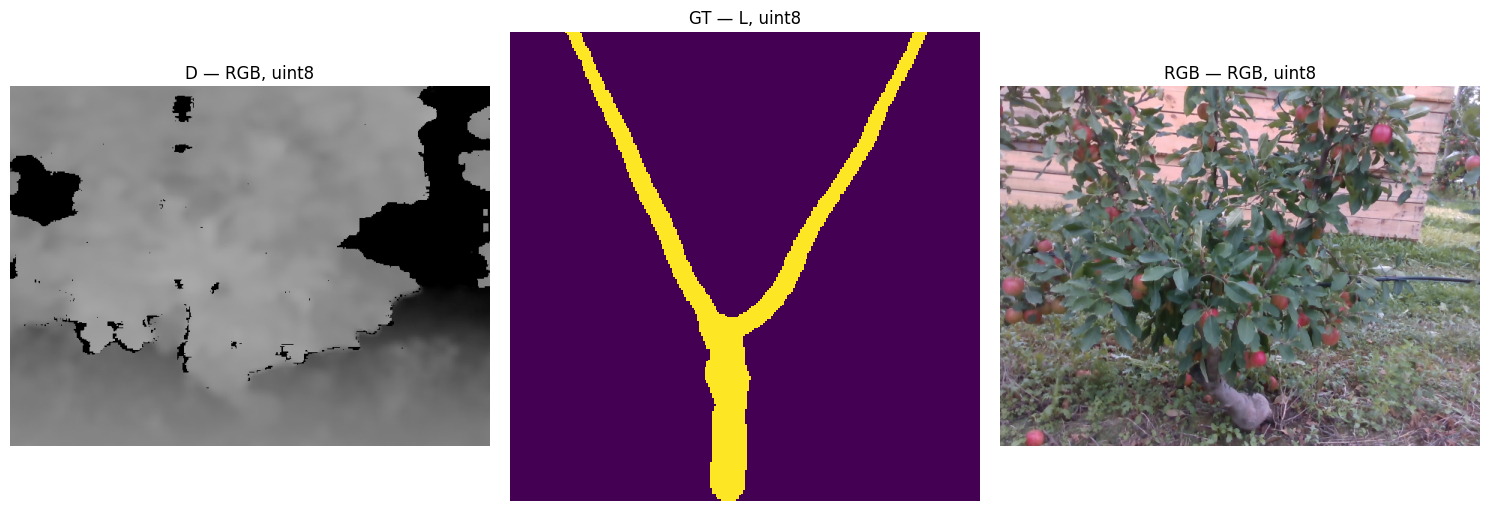

GT semantics unknown — inspect pixel values, shapes and provider notes.


In [ ]:

from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import csv

fig, axes = plt.subplots(1, len(paths), figsize=(5*len(paths), 5))
if len(paths) == 1:
    axes = [axes]

metadata = []

for ax, (kind, path) in zip(axes, sorted(paths.items())):
    with Image.open(path) as img:
        arr = np.asarray(img)
        mode = img.mode

    print(kind, '| Mode:', mode, '| Shape:', arr.shape,
          '| Type:', arr.dtype, '| Min:', arr.min(), '| Max:', arr.max())

    if arr.ndim == 2:
        ax.imshow(arr, cmap='viridis', interpolation='nearest')
    else:
        ax.imshow(arr[:, :, :3])

    ax.set_title(kind + ' — ' + mode + ', ' + str(arr.dtype))
    ax.axis('off')

    metadata.append([
        kind, path.name, mode, str(arr.shape),
        str(arr.dtype), int(arr.min()), int(arr.max())
    ])

plt.tight_layout()
plt.savefig(OUT / 'input_preview.png', dpi=160)
plt.show()

# Save image information as CSV instead of JSON
with open(OUT / 'image_diagnostics.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['Type', 'Filename', 'Mode', 'Shape',
                     'Data Type', 'Min', 'Max'])
    writer.writerows(metadata)

print('GT semantics unknown — inspect pixel values, shapes and provider notes.')


In [ ]:

from scipy.spatial import cKDTree
import csv
import time

# Load depth image
with Image.open(paths['D']) as img:
    raw = np.asarray(img)

# Convert RGB depth image to 2D only if channels are identical
if raw.ndim == 3:
    if not (np.array_equal(raw[:, :, 0], raw[:, :, 1]) and
            np.array_equal(raw[:, :, 1], raw[:, :, 2])):
        raise ValueError('Depth image channels are different.')
    depth = raw[:, :, 0]
else:
    depth = raw

# Check RGB image dimensions
with Image.open(paths['RGB']) as img:
    rgb = np.asarray(img.convert('RGB'))

print('Depth shape:', depth.shape)
print('RGB shape:', rgb.shape)
print('Dimensions match:', depth.shape == rgb.shape[:2])

# Split valid pixels into 90% training, 5% validation and 5% testing
pixels = np.argwhere(depth > 0)
order = np.random.default_rng(42).permutation(len(pixels))
n = int(len(pixels) * 0.05)

validation = pixels[order[:n]]
testing = pixels[order[n:2*n]]
training = pixels[order[2*n:]]

# Find neighbouring training pixels
tree = cKDTree(training)
values = depth[training[:, 0], training[:, 1]].astype(float)

results = []

for method in ('nearest', 'idw'):
    for stage, targets in (('validation', validation), ('test', testing)):
        start = time.perf_counter()

        k = 1 if method == 'nearest' else 8
        distances, indices = tree.query(
            targets, k=k, distance_upper_bound=6
        )

        if method == 'nearest':
            valid = np.isfinite(distances)
            predictions = values[np.minimum(indices, len(values)-1)]
        else:
            valid_neighbors = np.isfinite(distances)
            weights = np.where(
                valid_neighbors,
                1 / np.maximum(distances, 1e-10)**2,
                0
            )
            total = weights.sum(axis=1)
            valid = total > 0
            predictions = (
                (values[np.minimum(indices, len(values)-1)] * weights).sum(axis=1)
                / np.maximum(total, 1e-10)
            )

        actual = depth[targets[:, 0], targets[:, 1]]
        error = predictions[valid] - actual[valid]

        results.append({
            'method': method,
            'stage': stage,
            'rmse': float(np.sqrt(np.mean(error**2))) if len(error) else np.nan,
            'mae': float(np.mean(np.abs(error))) if len(error) else np.nan,
            'coverage': float(np.mean(valid)),
            'runtime_seconds': time.perf_counter() - start
        })

# Display results
for row in results:
    print(row)

# Save results as CSV
with open(OUT / 'interpolation_metrics.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=results[0].keys())
    writer.writeheader()
    writer.writerows(results)

print('Results saved to interpolation_metrics.csv')


Depth shape: (480, 640)
RGB shape: (480, 640, 3)
Dimensions match: True
{'method': 'nearest', 'stage': 'validation', 'rmse': 1.8957273820085685, 'mae': 0.35024368630926006, 'coverage': 1.0, 'runtime_seconds': 0.021240949999992154}
{'method': 'nearest', 'stage': 'test', 'rmse': 1.3710781396773732, 'mae': 0.34153005464480873, 'coverage': 1.0, 'runtime_seconds': 0.015378138999949442}
{'method': 'idw', 'stage': 'validation', 'rmse': 1.027821139547332, 'mae': 0.3163323587270466, 'coverage': 1.0, 'runtime_seconds': 0.03134195000006912}
{'method': 'idw', 'stage': 'test', 'rmse': 0.783167104847204, 'mae': 0.3125285253138997, 'coverage': 1.0, 'runtime_seconds': 0.03598456800000349}
Results saved to interpolation_metrics.csv


In [ ]:

import shutil
from google.colab import files

packet = Path('/content/MMA3001_appletree_dataset.zip')

shutil.make_archive(str(packet.with_suffix('')), 'zip', OUT)

print('Packet:', packet)
print('Size (MB):', round(packet.stat().st_size / 1e6, 2))

files.download(str(packet))


Packet: /content/MMA3001_appletree_dataset.zip
Size (MB): 1.82


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>